# LAB 4 — Regularization and Feature Selection | Active Lab

**This sheet is for you. Preparing for the exam starts here.**

Work in pairs: first write your own prediction, then compare explanations. For each main investigation follow **PREDICT → RUN & OBSERVE → EXPLAIN → EXPERIMENT**. The goal is to understand *why* results change, not just to execute the notebook.

**Core path:** Investigations 1–5 (split/scaling → baseline → Lasso → cross-validation → Ridge and final evaluation). **Going further:** explore different grids and future-data comparison if time permits.

**Files needed:** `kc_house_data/kc_house_data_reduced.csv` and, for the optional last section, `kc_house_data/kc_house_data_future.csv`. Keep the supplied directory structure. 
The files are available in the course webpage.


#  Regression on House Pricing Dataset: Regularization and Feature Selection
We consider a reduced version of a dataset containing house sale prices for King County, which includes Seattle. It consists in homes sold between May 2014 and May 2015.

Link to the dataset: https://www.kaggle.com/harlfoxem/housesalesprediction

For each house we know 18 house features (e.g., number of bedrooms, number of bathrooms, etc.) plus its price, that is what we would like to predict.

## Insert your ID number ("numero di matricola") below

In [41]:
# -- put here your ID Number ("numero di matricola")
ID_number = 2101846 # COMPLETE

In [42]:
# -- import all packages needed
# -- pandas: software library for data analysis and data manipulation
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

Load the data, remove data samples with missing values (NaN) and take a look at them.

In [43]:
# -- load the data (csv format)
df = pd.read_csv(os.path.join(os.getcwd(), "kc_house_data", "kc_house_data_reduced.csv"), sep = ",")

# -- remove the data samples with missing values (NaN)
df = df.dropna()

# -- print the column names and the first 5 rows of the dataframe
print(df.columns)
print('\n')
print(df.head())

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')


           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400

In [44]:
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,9510920070,20140710T000000,879000.0,4,2.50,3360,22111,2.0,0,0,...,10,3360,0,1994,0,98075,47.5951,-122.017,3150,11374
296,5468730030,20140822T000000,265000.0,3,2.00,1320,8959,1.0,0,0,...,7,1320,0,1993,0,98042,47.3536,-122.144,1740,7316
297,8079030390,20150304T000000,446500.0,3,2.50,2650,7286,2.0,0,0,...,8,2650,0,1990,0,98059,47.5084,-122.154,2400,7220
298,600000152,20140602T000000,404000.0,3,1.50,2030,8880,1.0,0,0,...,7,1330,700,1963,0,98108,47.5586,-122.311,2140,5592


In [45]:
# check in there is a numerical feature that has a low variance
df.var(numeric_only=True)

id               8.336115e+18
price            1.169352e+11
bedrooms         7.112598e-01
bathrooms        5.320123e-01
sqft_living      7.835507e+05
sqft_lot         7.390127e+08
floors           2.522046e-01
waterfront       1.319955e-02
view             5.935786e-01
condition        4.629989e-01
grade            1.186444e+00
sqft_above       5.531810e+05
sqft_basement    2.321007e+05
yr_built         8.003417e+02
yr_renovated     1.781850e+05
zipcode          2.796783e+03
lat              2.053185e-02
long             1.804789e-02
sqft_living15    4.388204e+05
sqft_lot15       3.996338e+08
dtype: float64

Separate input and output data. We want to predict the price by using features other than id and date as input.

In [46]:
data = df.values # removes headers 
m = df.shape[0]

print("Number of samples:", m)

permutation = np.random.default_rng(ID_number).permutation(m)

data = data[permutation,:]

Y = data[:m,2]
# -- explain why we are excluding ids (and date)
# these two feature are not useful for estimating the house price
X = data[:m,3:]

# -- print shapes
print("X shape: ", X.shape)
print("Y shape: ", Y.shape)

# description of input data X
pd.DataFrame(X, columns=df.columns[3:], dtype=float).describe()

Number of samples: 300
X shape:  (300, 18)
Y shape:  (300,)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,3.333333,2.013333,2055.496667,14193.926667,1.421667,0.013333,0.220000,3.456667,7.586667,1705.020000,350.476667,1966.690000,93.236667,98074.943333,47.544087,-122.224943,1952.770000,12555.270000
std,0.843362,0.729392,885.183995,27184.787381,0.502200,0.114889,0.770441,0.680440,1.089240,743.761357,481.768276,28.290311,422.119640,52.884617,0.143289,0.134342,662.435198,19990.842449
min,1.000000,0.750000,700.000000,1044.000000,1.000000,0.000000,0.000000,1.000000,5.000000,580.000000,0.000000,1900.000000,0.000000,98001.000000,47.197600,-122.451000,830.000000,1106.000000
25%,3.000000,1.500000,1367.500000,5230.000000,1.000000,0.000000,0.000000,3.000000,7.000000,1167.500000,0.000000,1949.000000,0.000000,98031.000000,47.427150,-122.339000,1450.000000,5075.000000
50%,3.000000,2.000000,1960.000000,8088.500000,1.000000,0.000000,0.000000,3.000000,7.000000,1545.000000,0.000000,1968.000000,0.000000,98059.000000,47.555950,-122.255000,1790.000000,7940.000000
75%,4.000000,2.500000,2480.000000,11216.250000,2.000000,0.000000,0.000000,4.000000,8.000000,2161.250000,650.000000,1988.250000,0.000000,98117.000000,47.676350,-122.148500,2332.500000,10391.750000
max,6.000000,4.750000,5420.000000,315374.000000,3.000000,1.000000,4.000000,5.000000,12.000000,5310.000000,2060.000000,2014.000000,2013.000000,98199.000000,47.773100,-121.711000,4760.000000,193842.000000


## Data Pre-Processing

We split the data (with $m = 300$ samples) into 2 parts: 
* Training set: data samples used for optimizing the model parameters (we set $m_{train}=60$ samples);
* Test set: data samples for assessing generalization performance (the remaining ones, i.e., $m_{test}=240$ samples).
We deliberately use a small training set (60 observations) and a larger test set (240 observations).

This is not a typical split, but it allows us to investigate how regularization behaves when training data are scarce. Notice that cross-validation estimates may be unstable because each validation fold contains only a few observations.

In [47]:
# -- Split data into train (60 = 1/5 of samples) and test (the rest)
m_train = int(1/5 * m)
m_test = m - m_train 

# -- print sizes
print("Amount of data for training and deciding parameters:", m_train)
print("Amount of data for test:", m_test)

Amount of data for training and deciding parameters: 60
Amount of data for test: 240


In [48]:
# -- let's use built-in function from scikit-learn to split the data
from sklearn.model_selection import train_test_split

# -- look at the documentation: we need to do train_test_split:
# -- first, we split data into train and test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = m_test, random_state=ID_number)

In [49]:
# -- let's check if the sizes match
print(f'X_train size: {X_train.shape}, Y_train size: {Y_train.shape}')
print(f'X_test size: {X_test.shape}, Y_test size: {Y_test.shape}')

X_train size: (60, 18), Y_train size: (60,)
X_test size: (240, 18), Y_test size: (240,)


Let's standardize the data.

In [50]:
# -- data pre-processing (leave to studs)
from sklearn import preprocessing
scaler = preprocessing.StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [51]:
# -- let's check if the scaler did his job
print(f'X_train mean: {np.mean(X_train_scaled, axis=0)}, \nX_train std: {np.std(X_train_scaled, axis=0)}')

X_train mean: [-1.07321559e-16  1.17498603e-16  5.55111512e-18 -6.01370805e-18
  6.29126381e-17  3.33066907e-17 -6.29126381e-17 -1.49880108e-16
  3.05311332e-16 -1.14723046e-16 -1.99840144e-16 -1.62832710e-15
  6.19874522e-17  1.73712896e-14 -2.83391366e-14  2.35907590e-13
  1.54506038e-16 -6.47630098e-17], 
X_train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [52]:
print(f'X_test mean: {np.mean(X_test_scaled, axis=0)}, \nX_test std: {np.std(X_test_scaled, axis=0)}')

X_test mean: [-0.02562789  0.0974466   0.40812805  0.1770369   0.07251465 -0.03254723
 -0.06832602 -0.04495801  0.31320572  0.22176915  0.41225759  0.1729055
 -0.01952869 -0.22686747  0.002219    0.17114404  0.3721114   0.55104487], 
X_test std: [1.04439848 0.94802126 1.21616824 1.42243189 0.96117165 0.86785826
 0.87385596 0.89380553 1.08460071 1.05343256 1.41704947 1.05258898
 0.95765581 0.92717285 1.12862532 0.93955556 1.22165987 2.68552472]


Depending on the seed, some features can have std = 0 after scaling, because with only 60 training samples a rare feature (e.g. waterfront, 4/200 houses) can be exactly constant in the training set. The scaled column is then all zeros and the model cannot learn from it.

### Investigation 1 — A baseline before regularization

**PREDICT:** What does ordinary least squares minimize? Do you expect a model with more nonzero coefficients to necessarily generalize better?

**RUN & OBSERVE:** Fit `LinearRegression`, inspect its coefficients and **training** MSE. House prices are large numbers, so squared errors are large too.

**EXPLAIN:** Define MSE and R². Which is their unit of measurement?

**EXPERIMENT:** Compare the sizes/signs of the coefficients. Which ones would you hesitate to interpret causally? Why?


## Least-Squares Solution

Now, let's compute the <u>Least-Squares</u> estimate using **LinearRegression** class in Scikit-learn, and then let's print the corresponding average loss (MSE loss) in training and test data.

Because prices are measured in large units, the MSE can be numerically large. We also report $R^2$ (and $1-R^2$), a dimensionless score relative to predicting the target mean. 

In [53]:
# -- Least-Squares
from sklearn import linear_model 
# -- LR the linear regression model
LR = linear_model.LinearRegression()

# -- fit the model on training data
LR.fit(X_train_scaled, Y_train)

# -- obtain predictions on training data
Y_train_predicted = LR.predict(X_train_scaled)
Y_test_predicted = LR.predict(X_test_scaled)

# -- coefficients from the model (explain horizontal stack)
w_LR = np.hstack((LR.intercept_, LR.coef_))
print('Linear Regressor parameters:\n', w_LR)

# -- average error in training data
loss_train = np.mean((Y_train - Y_train_predicted)**2) # alternatively: loss_train = np.linalg.norm(Y_train - Y_train_predicted)**2 / m_train
print('---')

# -- average error in test data
loss_test = np.mean((Y_test - Y_test_predicted)**2)
print(f'Average loss in test data: {loss_test} || {loss_test:.3e}')
print('---')
# -- print average loss in training data and in test data. Explain the high values of parameters (due to very high house prices)
print(f'Average loss in training data: {loss_train} || {loss_train:.3e}')
print('---')

# -- print coefficient of determination in training data and in test data
print(f'R² on training data:   {(LR.score(X_train_scaled, Y_train))}')


Linear Regressor parameters:
 [ 497521.26666668  -26212.14428799   25671.82668591  155603.10281833
  -13943.61856613  -54396.62577641   53054.38997567  -29020.90182246
  -49312.69015703   64237.58993976  176066.76003522  -25593.22215532
 -104685.09196399  107153.9587311   -80314.53686138  135911.92022327
  -26867.7863482   -76090.67914749   53373.29065261]
---
Average loss in test data: 118989682945.06613 || 1.190e+11
---
Average loss in training data: 16215413247.519897 || 1.622e+10
---
R² on training data:   0.8957029812186177


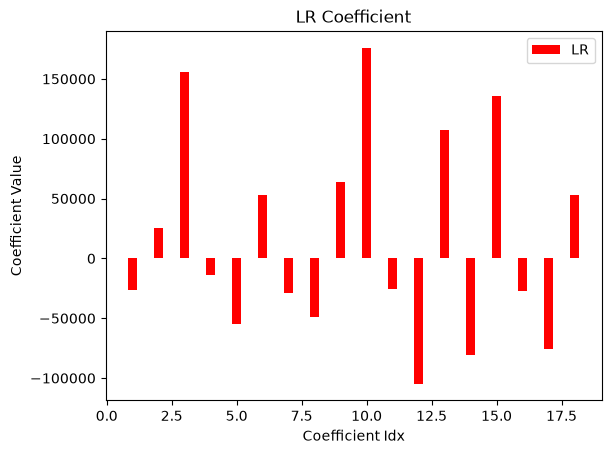

In [54]:
# -- define the x locations for the groups
ind = np.arange(1, len(LR.coef_) + 1)

# -- define the width of the bars
width = 0.35 

fig, ax = plt.subplots()
rects1 = ax.bar(ind, LR.coef_, width, color='r', label='LR')
ax.legend()
plt.xlabel('Coefficient Idx')
plt.ylabel('Coefficient Value')
plt.title('LR Coefficient')
plt.show()

### Investigation 2 — Lasso: regularization and sparsity

**PREDICT (before running the path):** As L1 regularization gets stronger (larger `alpha`, called λ in the lectures), what should happen to the number of nonzero coefficients? Must validation error keep decreasing?

**RUN & OBSERVE:** Plot the number of nonzero coefficients across the supplied `alpha` grid. Observe where the model becomes sparse.

**EXPLAIN:** Lasso penalizes the absolute values of coefficients; it can set some of them exactly to zero. 

**EXPERIMENT:** Change the range of `lasso_lams` (the grid), not the test set. Can you find a range that reveals the transition from many nonzero coefficients to very few?


-- -
# Regularization

## L1 Regularization and Lasso

We use the routine *lasso_path* from *sklearn.linear_model* to compute the "lasso path", which corresponds to finding the models with lasso for different values of the regularization parameter $\lambda$. You should first fix a grid of possible values for lambda (the variable "lasso_lams"). For each entry of the vector "lasso_lams" we compute the corresponding model (i.e., the $i$-th column of the vector  "lasso_coefs" should contain the coefficients of the linear model computed using lasso_lams[$i$] as regularization parameter). In general, it is recommended to choose the grid appropriately.

<u>Note</u>: the parameter $\lambda$ is called $\alpha$ in the Lasso model from sklearn


### Option A — Interactive exploration of the Lasso path

Use the widgets to choose the grid of regularization parameters and the number of CV folds, then press **Run Interact**. For each choice the cell:

1. computes the Lasso path on a log-spaced grid of 100 values between `alpha min` and `alpha max`;
2. runs $k$-fold cross-validation on the training set (the scaler is fitted inside each training fold);
3. selects $\alpha_{opt}$ as the value with the lowest validation loss and refits Lasso on the whole training set.

The green dashed line marks $\alpha_{opt}$ on both plots.

**Things to try:**
- Is `alpha max` large enough for **all** coefficients to become zero? If not, increase it.
- Is $\alpha_{opt}$ at one end of the grid? If so, the grid should be extended.
- How do the validation curve and $\alpha_{opt}$ change when you change the number of folds? With only 60 training samples, many folds mean very small validation sets.

> The cell updates `lasso_lams`, `lasso_lam_opt` and `lasso_reg`, which are used in the following cells.

In [55]:
import ipywidgets as widgets
from sklearn.linear_model import lasso_path
from sklearn.model_selection import KFold

def run_lasso(alpha_min=1.0, alpha_max=1e6, num_folds=5):
    global lasso_lams, lasso_lam_opt, lasso_reg   # used by the following cells

    lasso_lams = np.geomspace(alpha_min, alpha_max, num=100)
    lasso_lams, lasso_coefs, _ = lasso_path(X_train_scaled, Y_train, alphas=lasso_lams)

    # -- k-fold CV (scaler fitted inside each training fold)
    loss_train = np.zeros(len(lasso_lams))
    loss_val = np.zeros(len(lasso_lams))
    for tr, va in KFold(n_splits=num_folds).split(X_train):
        sc = preprocessing.StandardScaler().fit(X_train[tr])
        Xtr, Xva = sc.transform(X_train[tr]), sc.transform(X_train[va])
        for i, lam in enumerate(lasso_lams):
            model = linear_model.Lasso(alpha=lam, tol=0.05).fit(Xtr, Y_train[tr])
            loss_train[i] += np.mean((Y_train[tr] - model.predict(Xtr))**2) / num_folds
            loss_val[i] += np.mean((Y_train[va] - model.predict(Xva))**2) / num_folds

    lasso_lam_opt = lasso_lams[np.argmin(loss_val)]
    lasso_reg = linear_model.Lasso(alpha=lasso_lam_opt).fit(X_train_scaled, Y_train)

    # -- plots
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(lasso_lams, (lasso_coefs != 0).sum(axis=0), marker='o', markersize=4)
    ax[0].set(xscale='log', xlabel='Alpha', ylabel='Non-zero coefficients', title='Sparsity Degree')
    ax[1].plot(lasso_lams, loss_train, 'r-x', label='Train')
    ax[1].plot(lasso_lams, loss_val, 'b-x', label='Validation')
    ax[1].set(xscale='log', xlabel='Alpha', ylabel='Loss', title='Lasso: choice of alpha')
    ax[1].legend()
    for a in ax:
        a.axvline(lasso_lam_opt, color='g', ls='--')
    plt.show()

    print('Best alpha:', lasso_lam_opt)
    print('Non-zero coefficients:', np.sum(lasso_reg.coef_ != 0), '/', len(lasso_reg.coef_))

widgets.interact_manual(
    run_lasso,
    alpha_min=widgets.FloatLogSlider(value=1, min=-3, max=4, step=0.1, description='alpha min'),
    alpha_max=widgets.FloatLogSlider(value=1e6, min=2, max=8, step=0.1, description='alpha max'),
    num_folds=widgets.IntSlider(value=5, min=2, max=10, description='# folds'),
)


interactive(children=(FloatLogSlider(value=1.0, description='alpha min', min=-3.0), FloatLogSlider(value=10000…

<function __main__.run_lasso(alpha_min=1.0, alpha_max=1000000.0, num_folds=5)>

### Option B — Step-by-step version

The cells below perform the same steps one at a time, with a fixed grid: Lasso path, sparsity plot, $k$-fold cross-validation and final fit. Use them to follow the code in detail, or if widgets are not available in your environment.

> If you run both options, the following cells use the results of the **last** one you ran.

In [56]:
from sklearn.linear_model import lasso_path

# select a grid of possible regularization parameters 
# (be careful how this is chosen, you may have to refine the choice after having seen the results)

lasso_lams = np.logspace(0, 6, num = 100) 

#NOTE: YOU NEED TO REACH VALUES OF THE REGULARIZATION PARAMETER 
#THAT LEAD TO ALL FEATURES HAVING WEIGHT EQUAL TO ZERO.
#To achieve this, you may have to change the maximum value considered for the 
#regularization parameters, for example using:
#logspace(0, 6, num = 100), then change its value

In [57]:
# Use the function lasso_path to compute the "lasso path", passing in input the lambda values
# you have specified in lasso_lams
lasso_lams, lasso_coefs, _ = lasso_path(X_train_scaled, Y_train, alphas = lasso_lams) 

We evaluate the sparsity (i.e., number of non-zero coefficients) in the estimated coefficients as a function of the regularization parameter $\lambda$: to this purpose, we compute the number of non-zero entries in the estimated coefficient vector.

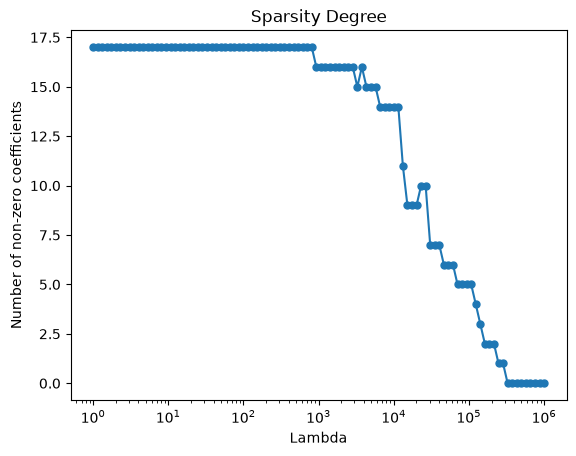

In [58]:
l0_coef_norm = np.zeros(len(lasso_lams),)

for i in range(len(lasso_lams)):
    l0_coef_norm[i] = sum(lasso_coefs[:,i]!=0)


plt.plot(lasso_lams, l0_coef_norm, marker='o', markersize=5)
plt.xlabel('Lambda')
plt.ylabel('Number of non-zero coefficients')
plt.title('Sparsity Degree')
plt.xscale('log')
plt.show()

### Investigation 3 - Use $k$-fold Cross-Validation to fix the regularization parameter

Now, we need to decide which value of $\lambda$ to use. In order to do this, we are going to use $k$-fold Cross-Validation.

We are going to use the scikit-learn built-in routine *Lasso* (from the *linear_model* package) to compute the lasso coefficients.

We use *KFold* from *sklearn.model_selection* to split the data (i.e. X_train and Y_train) into the desired number of folds.

Then we pick $\lambda_{opt}$ to be the chosen value for the regularization parameter.

#### $k$-fold Cross-Validation

Given $m$, we partition the training set into $k$ folds of size $m/k$. For each fold:

* 1 - perform the training on the union of the other $(k-1)$ folds;
* 2 - treat the left-out fold as a *small validation set*, and estimate the error of the learned hypothesis.

$\longrightarrow$ The final estimate of the true error will be the average of the estimated errors through all the folds, as described above.

When $k = m$, we refer to the above procedure as *leave-one out* validation.

Beside hyperparameter selection, cross validation is often used for model selection and feature selection.

At the end, the final hypothesis is obtained from training on the entire training set. What about standardization?

In [59]:
from sklearn.model_selection import KFold

num_folds = 5

kf = KFold(n_splits = num_folds)

loss_train_lasso_kfold = np.zeros(len(lasso_lams),)
loss_val_lasso_kfold = np.zeros(len(lasso_lams),)
R2_train_lasso_kfold = np.zeros(len(lasso_lams),)
R2_val_lasso_kfold = np.zeros(len(lasso_lams),)


for i, lam in enumerate(lasso_lams):
    # -- 1) define a Lasso model for this candidate alpha
    lasso_kfold = linear_model.Lasso(alpha=lam, tol=0.05)
    # -- tolerance alternative: lasso_kfold = linear_model.Lasso(alpha=lasso_lams[i], tol=0.1)
    for train_index, validation_index in kf.split(X_train):
        
        X_train_kfold, X_val_kfold = X_train[train_index], X_train[validation_index]
        Y_train_kfold, Y_val_kfold = Y_train[train_index], Y_train[validation_index]
        
        # -- data scaling
        scaler_kfold = preprocessing.StandardScaler().fit(X_train_kfold)
        X_train_kfold = scaler_kfold.transform(X_train_kfold)
        X_val_kfold = scaler_kfold.transform(X_val_kfold)
    
        # -- learn the model using the training data from the k-fold
        lasso_kfold.fit(X_train_kfold, Y_train_kfold)
        # -- compute the loss using the train and validation data from the k-fold
        Y_pred_train = lasso_kfold.predict(X_train_kfold)
        Y_pred_val = lasso_kfold.predict(X_val_kfold) 
        # -- incremental mean
        loss_train_lasso_kfold[i] += np.mean((Y_train_kfold - Y_pred_train)**2)
        loss_val_lasso_kfold[i] += np.mean((Y_val_kfold - Y_pred_val)**2)
        R2_train_lasso_kfold[i] += (lasso_kfold.score(X_train_kfold, Y_train_kfold))
        R2_val_lasso_kfold[i] += (lasso_kfold.score(X_val_kfold, Y_val_kfold))

# -- compute the mean => estimate of train and validation losses and errors for each lam
loss_train_lasso_kfold /= num_folds
loss_val_lasso_kfold /= num_folds
R2_train_lasso_kfold /= num_folds
R2_val_lasso_kfold /= num_folds


# -- choose the regularization parameter that minimizes the validation loss
lasso_lam_opt = lasso_lams[np.argmin(loss_val_lasso_kfold)]
print('Best value of the regularization parameter:', lasso_lam_opt)
print('Min MSE: ', np.min(loss_val_lasso_kfold))
print('max R²', np.max(R2_val_lasso_kfold))


Best value of the regularization parameter: 3764.9358067924672
Min MSE:  98785521875.46526
max R² -0.06611462674251042


Let's plot the Cross-Validation estimates of the loss as a function of the regularization parameter.

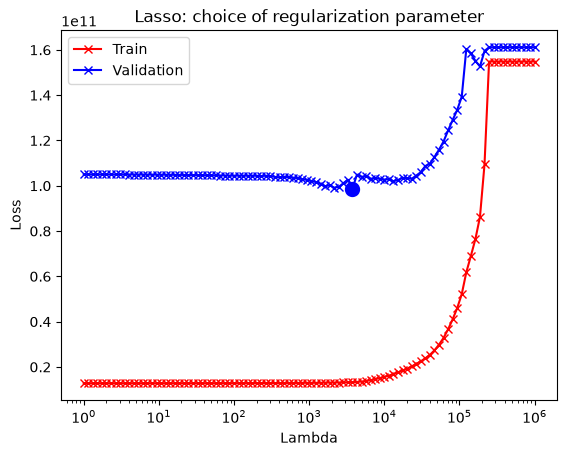

Total number of coefficients: 18
Number of non-zero coefficients: 16
Best value of regularization parameter: 3764.9358067924672


In [60]:
plt.xscale('log')
plt.plot(lasso_lams, loss_train_lasso_kfold, color='r', marker='x')
plt.plot(lasso_lams, loss_val_lasso_kfold, color='b', marker='x')
plt.scatter(lasso_lams[np.argmin(loss_val_lasso_kfold)], loss_val_lasso_kfold[np.argmin(loss_val_lasso_kfold)], color='b', marker='o', linewidths=5)
plt.legend(['Train', 'Validation'])
plt.xlabel('Lambda')
plt.ylabel('Loss')
plt.title('Lasso: choice of regularization parameter')
plt.show()

# -- fit lasso model using the optimal value of the reg. parameter lasso_lam_opt found with k-fold cross validation
lasso_kfold = linear_model.Lasso(alpha=lasso_lam_opt)
lasso_kfold.fit(X_train_scaled, Y_train)

print('Total number of coefficients:', (len(lasso_kfold.coef_)))
print('Number of non-zero coefficients:', (sum(lasso_kfold.coef_ != 0)))
print('Best value of regularization parameter:', (lasso_lam_opt))



## Now let's estimate the lasso coefficients using all the training data and the optimal regularization parameter (chosen at previous step)

Note that we use all the training data to learn the final model for the optimal regularization parameter (once we have chosen the parameter, there is no reason to use less data than what we have). We leave out only the test data so that we can later use it to estimate the generalization error.

In [70]:
# -- estimate Lasso coefficients with all data (X_train_scaled) using the optimal value lasso_lam_opt of the regularization parameter
# lasso_lams, lasso_coefs, _ = lasso_path(X_test_scaled, Y_test, alphas = lasso_lams) 

# -- define the model
lasso_reg = linear_model.Lasso(alpha=lasso_lam_opt)

# -- fit using the training data
lasso_reg.fit(X_train_scaled, Y_train)

# -- average loss on training data
loss_train_lasso = np.mean((Y_train - lasso_reg.predict(X_train_scaled))**2)

# -- print average loss in training data and in test data
print('Average loss in training data:', loss_train_lasso)

# -- now print the coefficient of determination on training and on test data to get an idea to what the average
# -- loss corresponds to
print('R² on training data:  ', lasso_reg.score(X_train_scaled, Y_train))





Average loss in training data: 17330416262.569427
R² on training data:   0.8885313175288436


## We now compare the coefficients from the LR model and the Lasso model

Note that we do not plot the bias

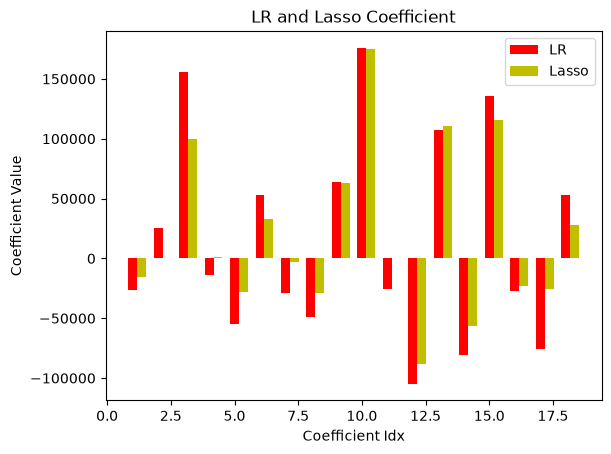

In [71]:
# -- compare LR and lasso coefficients
# -- define the x locations for the groups
ind = np.arange(1, len(LR.coef_) + 1)

# -- define the width of the bars
width = 0.35 

fig, ax = plt.subplots()
rects1 = ax.bar(ind, LR.coef_, width, color='r')
rects2 = ax.bar(ind + width, lasso_reg.coef_, width, color='y')
ax.legend((rects1[0], rects2[0]), ('LR', 'Lasso'))
plt.xlabel('Coefficient Idx')
plt.ylabel('Coefficient Value')
plt.title('LR and Lasso Coefficient')
plt.show()

#### Investigation 4 — Ridge vs Lasso: what changes?

**PREDICT:** Does L2 regularization typically set coefficients exactly to zero, as Lasso can? What happens to coefficient magnitudes as `alpha` increases?

**RUN & OBSERVE:** Select Ridge `alpha` by 5-fold CV, refit on the full training set, and compare coefficients with ordinary least squares and Lasso.

**EXPLAIN:** Ridge typically *shrinks* coefficients; Lasso can also produce *sparse* solutions. Both methods trade fit against a penalty. The selected `alpha` values are not directly comparable as equal regularization strengths across L1 and L2.

**EXPERIMENT:** Pick one coefficient that differs markedly across models and suggest a possible reason (e.g., correlated predictors).


## Ridge Regression

### Use Ridge regression with cross-validation

We perform the L2 regularization for different values of the regularization parameter $\alpha$ (called $\lambda$ in class), and use the Scikit-learn function to perform cross-validation (CV).

In Ridge regression for scikit learn, the objective function is:

$$
    ||y - Xw||^2_2 + \alpha * ||w||^2_2
$$

For this regression task, we use ordinary `KFold`. The scaler must be fitted separately within each training fold.

In the code below:
- we use `KFold` with `Ridge()` to compare candidate values of $\alpha$;
- we use Ridge() to learn the best model for the best $\alpha$ for ridge regression using the entire training set.

The code uses an explicit grid of candidate `alpha` values for Ridge, similar in form to the Lasso grid.




In [ ]:
from typing import Any


from sklearn.model_selection import KFold

num_folds = 5

ridge_alphas = np.logspace(0, 6, num = 100)
kf = KFold(n_splits = num_folds)

loss_train_ridge_kfold = np.zeros(len(ridge_alphas),)
loss_val_ridge_kfold = np.zeros(len(ridge_alphas),)
R2_train_ridge_kfold = np.zeros(len(ridge_alphas),)
R2_val_ridge_kfold = np.zeros(len(ridge_alphas),)


for i, alpha in enumerate(ridge_alphas):
    # -- 1) define a ridge model using Ridge() for the i-th value of alpha_values
    ridge_kfold = linear_model.Ridge(alpha=alpha)

    for train_index, validation_index in kf.split(X_train):
        
        X_train_kfold, X_val_kfold = X_train[train_index], X_train[validation_index]
        Y_train_kfold, Y_val_kfold = Y_train[train_index], Y_train[validation_index]
        
        # -- data scaling
        scaler_kfold = preprocessing.StandardScaler().fit(X_train_kfold)
        X_train_kfold = scaler_kfold.transform(X_train_kfold)
        X_val_kfold = scaler_kfold.transform(X_val_kfold)
    
        # -- learn the model using the training data from the k-fold
        ridge_kfold.fit(X_train_kfold, Y_train_kfold)
        # -- compute the loss using the train and validation data from the k-fold
        Y_pred_train = ridge_kfold.predict(X_train_kfold)
        Y_pred_val = ridge_kfold.predict(X_val_kfold) 
        # -- incremental mean
        loss_train_ridge_kfold[i] += np.mean((Y_train_kfold - Y_pred_train)**2)
        loss_val_ridge_kfold[i] += np.mean((Y_val_kfold - Y_pred_val)**2)
        R2_train_ridge_kfold[i] += (ridge_kfold.score(X_train_kfold, Y_train_kfold))
        R2_val_ridge_kfold[i] += (ridge_kfold.score(X_val_kfold, Y_val_kfold))

# -- compute the mean => estimate of train and validation losses and errors for each lam
loss_train_ridge_kfold /= num_folds
loss_val_ridge_kfold /= num_folds
R2_train_ridge_kfold /= num_folds
R2_val_ridge_kfold /= num_folds


# -- choose the regularization parameter that minimizes the validation loss
ridge_alpha_opt = ridge_alphas[np.argmin(loss_val_ridge_kfold)]
print('Best value of the regularization parameter:', ridge_alpha_opt)
print('Min MSE: ', np.min(loss_val_ridge_kfold))
print('Max R² ', np.max(R2_val_ridge_kfold))


Let's plot the Training and Validation error as a function of the regularization parameter for Ridge Regression

In [ ]:
plt.xscale('log')
plt.plot(ridge_alphas, loss_train_ridge_kfold, color='r', marker='x')
plt.plot(ridge_alphas, loss_val_ridge_kfold, color='b', marker='x')
plt.scatter(ridge_alphas[np.argmin(loss_val_ridge_kfold)], loss_val_ridge_kfold[np.argmin(loss_val_ridge_kfold)], color='b', marker='o', linewidths=5)
plt.legend(['Train', 'Validation'])
plt.xlabel('Alphas')
plt.ylabel('Loss')
plt.title('Ridge Regression: choice of regularization parameter')
plt.show()





## Now let's estimate the ridge coefficients using all the training data and the optimal regularization parameter (chosen at previous step)

Note that we use all the training data to learn the final model for the optimal regularization parameter (once we have chosen the parameter, there is no reason to use less data than what we have). We leave out only the test data so that we can later use it to estimate the generalization error.

In [ ]:
# -- estimate Ridge coefficients on training data using the CV-selected ridge_alpha_opt

# -- define the model
ridge_reg = linear_model.Ridge(alpha=ridge_alpha_opt)

# -- fit using the training data
ridge_reg.fit(X_train_scaled, Y_train)

# -- average loss on training data
loss_train_ridge = np.mean((Y_train - ridge_reg.predict(X_train_scaled))**2)

# -- print best value of regularization parameter for Ridge Regression
print('Best value of regularization parameter:', (ridge_alpha_opt))

# -- print average loss in training data and in test data
print('Average loss in training data:', loss_train_ridge)

# -- now print 1 - the coefficient of determination on training and on test data to get an idea to what the average
# -- loss corresponds to
print('R² on training data:  ', ridge_reg.score(X_train_scaled, Y_train))


## We now compare the coefficients from the LR model, the lasso model, and the ridge model

In [ ]:

# -- define the x locations for the groups
ind = np.arange(1, len(LR.coef_) + 1)
# -- define the width of the bars
width = 0.25

fig, ax = plt.subplots()
rects1 = ax.bar(ind, LR.coef_, width, color='r')
rects2 = ax.bar(ind + width, lasso_reg.coef_, width, color='y')
rects3 = ax.bar(ind + 2*width, ridge_reg.coef_, width, color='b')
ax.legend((rects1[0], rects2[0], rects3[0]), ('LR', 'Lasso', 'Ridge'))
plt.xlabel('Coefficient Idx')
plt.ylabel('Coefficient Value')
plt.title('LR, Lasso, and Ridge Coefficient')
plt.show()

### Final evaluation — Only now inspect the test set

**PREDICT:** Which of the three fitted procedures do you expect to have the lowest test error? **Write a reason before running.**

**RUN & OBSERVE:** Compare the held-out test scores for least squares, Lasso and Ridge. Remember that **higher `R²` is better**.

**EXPLAIN:** Does a lower training error imply lower test error? Can a single random test split determine which algorithm is universally best?


## Now use all data but the test one to learn the best model (using the chosen model class and parameter, if any), and estimate its generalization error on the test data

In [ ]:
# The models are fitted on the original training data in the following cell.


In [ ]:
# -- compute best LR model on training data
LR = linear_model.LinearRegression()
LR.fit(X_train_scaled, Y_train)

# -- compute and print 1 - coefficient of determination for the best LR model
print("R² of LR on test data:   ", LR.score(X_test_scaled, Y_test))

# -- compute best lasso_reg model on training data
lasso_reg = linear_model.Lasso(alpha=lasso_lam_opt)
lasso_reg.fit(X_train_scaled, Y_train)

# -- compute and print 1 - coefficient of determination for the best lasso model
print("R² of lasso on test data:", lasso_reg.score(X_test_scaled, Y_test))

# -- compute best ridge model on training data
ridge_final = linear_model.Ridge(alpha = ridge_alpha_opt)
ridge_final.fit(X_train_scaled, Y_train)

# -- compute and print 1 - coefficient of determination for the best ridge model
print("R² of ridge on test data:", ridge_final.score(X_test_scaled, Y_test))

## Going further — Evaluate on a separate future dataset 

Let's now use the second dataset: kc_house_data_future.csv

Keep the scaler and model parameters learned from the original training set fixed. This is an external evaluation, not an opportunity to retune the models.

In [ ]:
# -- load the new data
df = pd.read_csv(os.path.join(os.getcwd(), "kc_house_data", "kc_house_data_future.csv"), sep = ",")

# -- remove the data samples with missing values (NaN)
df = df.dropna() 

print(df.info())

data = df.values

m_future = data.shape[0]
print('Number of samples', m_future)

X_future = data[:m_future,3:]
Y_future = data[:m_future,2]

# -- let's scale the new data with the scaler used at the beginning!
X_future_scaled = scaler.transform(X_future)

# -- compute and print coefficient of determination for the best LR model
print('R² of LR on future data:   ', LR.score(X_future_scaled, Y_future))

# -- compute and print coefficient of determination for the best lasso model
print('R² of lasso on future data:', lasso_reg.score(X_future_scaled, Y_future))

# -- compute and print coefficient of determination for the best ridge model
print('R² of ridge on future data:', ridge_final.score(X_future_scaled, Y_future))

### END OF LAB — Close the notebook

Individually, reconstruct from memory: (1) Why is fitting a scaler outside each CV training fold a form of leakage? (2) Why can Lasso set coefficients to zero while Ridge usually does not? (3) Why is the test set used only after selecting `alpha`? Compare with your partner.
